In [87]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8,5)


In [88]:
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
df_iris['species'] = df_iris['target'].map(dict(enumerate(iris.target_names)))
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


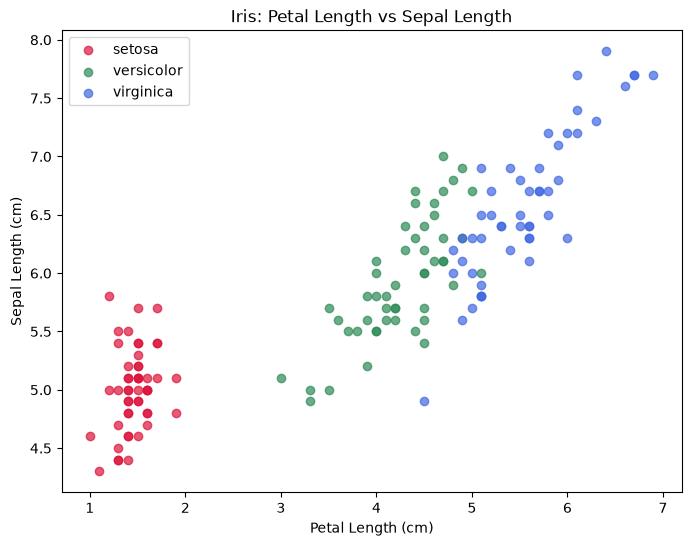

In [89]:
plt.figure(figsize=(8,6))
colors = {'setosa': 'crimson', 'versicolor': 'seagreen', 'virginica': 'royalblue'}
for sp, c in colors.items():
    subset = df_iris[df_iris['species'] == sp]
    plt.scatter(subset['petal length (cm)'],subset['sepal length (cm)'], label=sp,color=c,alpha=0.7)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Sepal Length (cm)')
plt.title('Iris: Petal Length vs Sepal Length')
plt.legend()
plt.show()

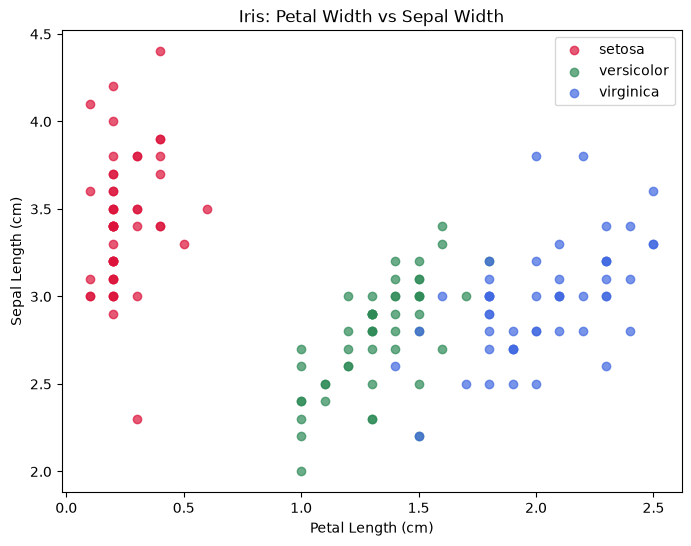

In [90]:
plt.figure(figsize=(8,6))
colors = {'setosa': 'crimson', 'versicolor': 'seagreen', 'virginica': 'royalblue'}
for sp, c in colors.items():
    subset = df_iris[df_iris['species'] == sp]
    plt.scatter(subset['petal width (cm)'],subset['sepal width (cm)'], label=sp,color=c,alpha=0.7)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Sepal Length (cm)')
plt.title('Iris: Petal Width vs Sepal Width')
plt.legend()
plt.show()

In [91]:
X = iris.data
X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [92]:
y = iris.target
y

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int64

In [93]:
feature_names = iris.feature_names
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
print("Train size:", X_train.shape, " Test size:", X_test.shape)


Train size: (105, 4)  Test size: (45, 4)


In [94]:
clf = DecisionTreeClassifier(criterion="entropy",max_depth=3,random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
accuracy = metrics.accuracy_score(y_test,y_pred)
print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 93.33%


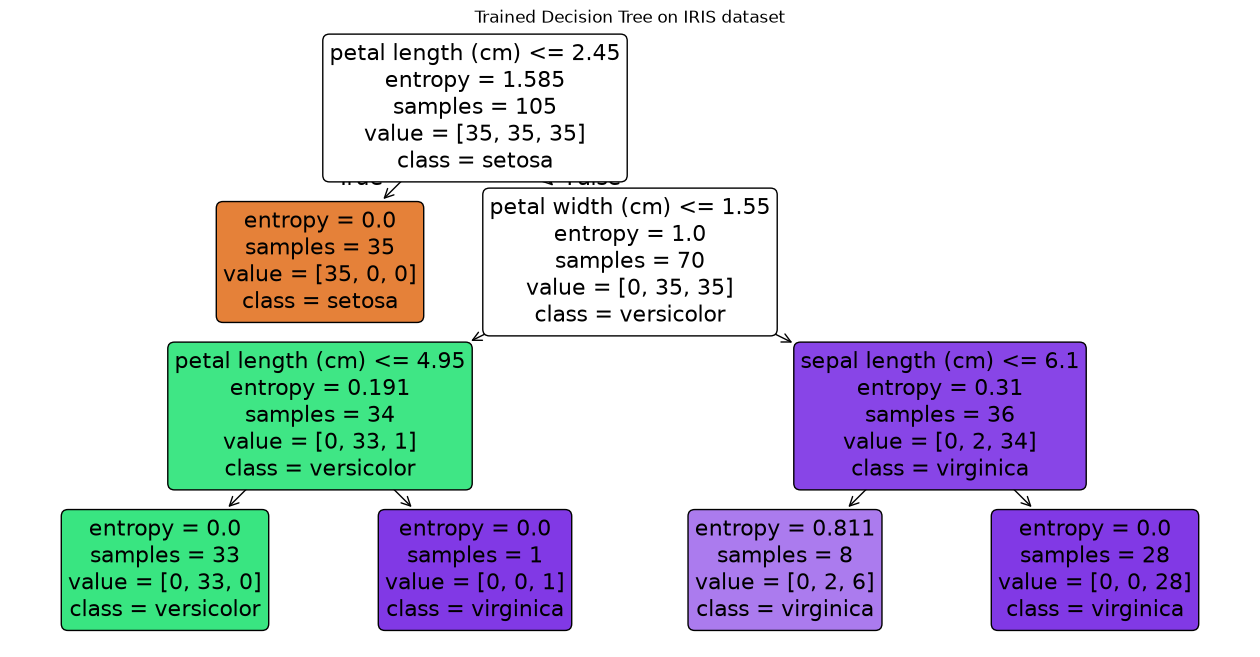

In [95]:
plt.figure(figsize=(16,8))
plot_tree(clf,feature_names=feature_names,class_names=class_names,filled=True,rounded=True,)
plt.title('Trained Decision Tree on IRIS dataset')
plt.show()

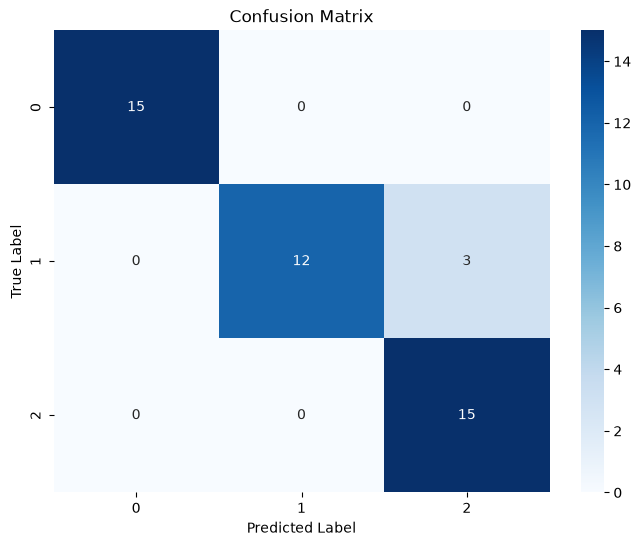

In [96]:
from sklearn.metrics import confusion_matrix
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt='d',cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title("Confusion Matrix")
plt.show()

In [97]:
from sklearn.metrics import classification_report,roc_auc_score,f1_score

y_proba = clf.predict_proba(X_test)

auc = roc_auc_score(
    y_test,
    y_proba,
    multi_class='ovr',
    average='weighted'
)
f1 = f1_score(y_test,y_pred,average='weighted')
print('Classification Report')
print(classification_report(y_test,y_pred,target_names=class_names))
print(f"AUC ROC: {auc:.4f}")
print(f"F1 Score: {f1:.4f}")


Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45

AUC ROC: 0.9600
F1 Score: 0.9327


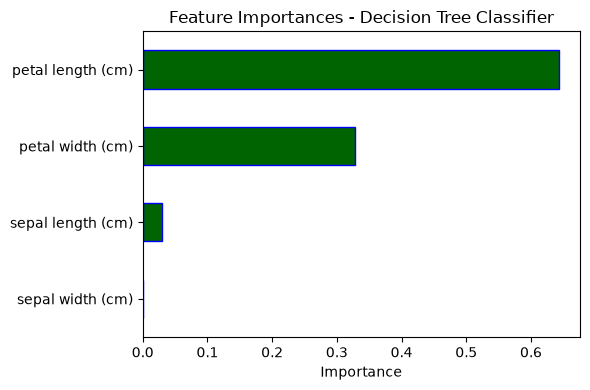

In [98]:
importance_classes = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(6,4))
importance_classes.plot(kind='barh',color='darkgreen',edgecolor='blue')
plt.title("Feature Importances - Decision Tree Classifier")
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

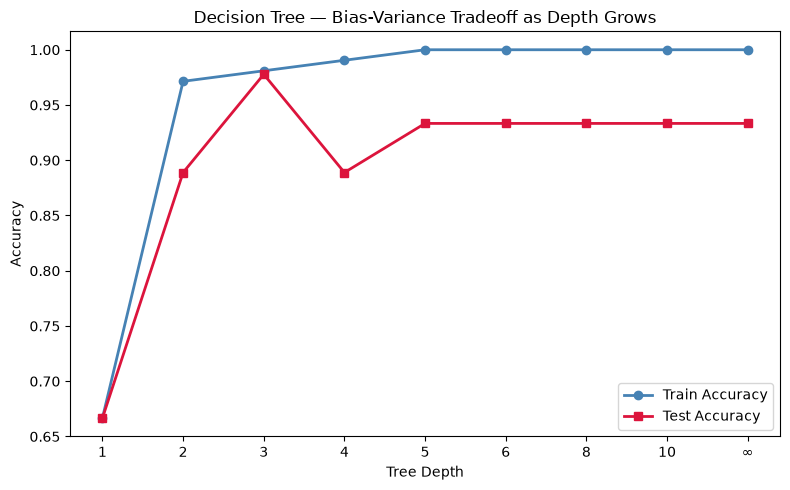

In [99]:
depths   = [1, 2, 3, 4, 5, 6, 8, 10, None]
train_accuracy, test_accuracy = [], []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_accuracy.append(metrics.accuracy_score(y_train, dt.predict(X_train)))
    test_accuracy.append(metrics.accuracy_score(y_test, dt.predict(X_test)))

depth_labels = [str(d) if d is not None else "∞" for d in depths]

plt.figure(figsize=(8, 5))
plt.plot(depth_labels, train_accuracy, "o-", color="steelblue",  linewidth=2, label="Train Accuracy")
plt.plot(depth_labels, test_accuracy,  "s-", color="crimson",    linewidth=2, label="Test Accuracy")

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree — Bias-Variance Tradeoff as Depth Grows")
plt.legend()
plt.tight_layout()
plt.show()

In [100]:
path = clf.cost_complexity_pruning_path(X_train,y_train)
path

{'ccp_alphas': array([0.        , 0.04431751, 0.06198791, 0.49854958, 0.91829583]),
 'impurities': array([0.06181167, 0.10612918, 0.16811709, 0.66666667, 1.5849625 ])}

In [101]:
ccp_alphas = path.ccp_alphas
ccp_alphas

array([0.        , 0.04431751, 0.06198791, 0.49854958, 0.91829583])

In [102]:
pruned_models = []
for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        criterion='entropy',
        random_state=42,
        ccp_alpha=alpha,
    )
    model.fit(X_train,y_train)
    pruned_models.append(model)


In [103]:
best_accuracy = -0
best_pruned_model = None

for model in pruned_models:
    score = model.score(X_test,y_test)
    if best_accuracy < score:
        best_accuracy = score
        best_pruned_model = model 

print(f"Best Accuracy : {best_accuracy*100:.2f}%")

Best Accuracy : 93.33%


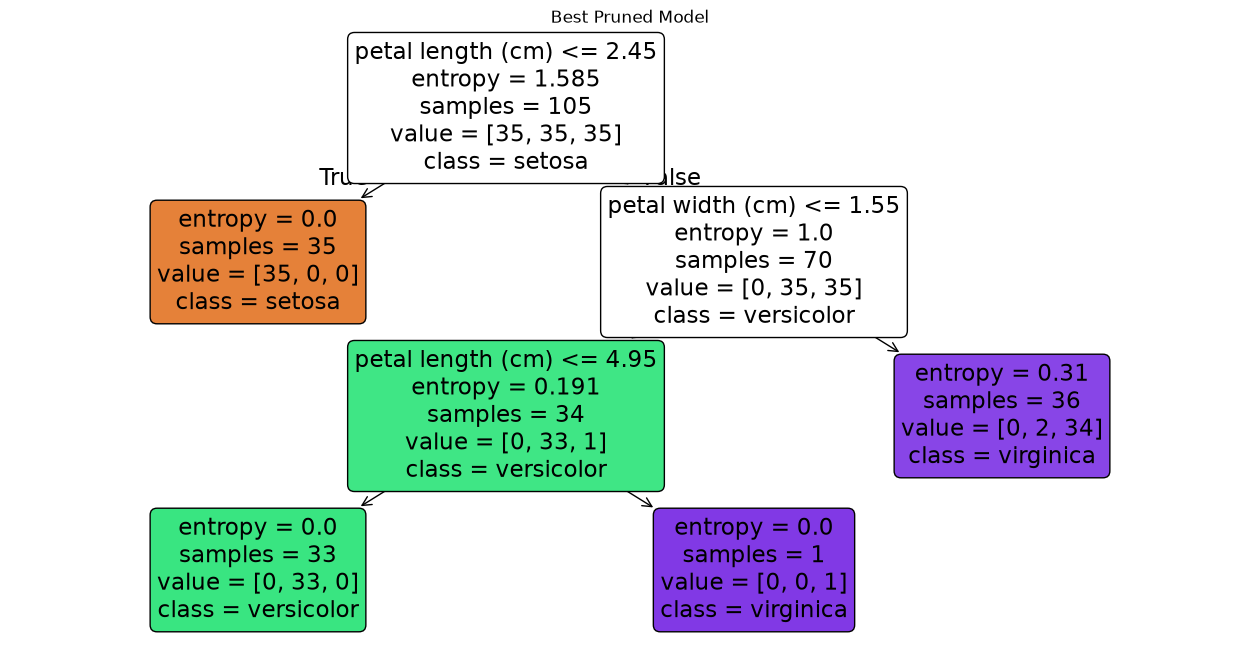

In [104]:
plt.figure(figsize=(16,8))
plot_tree(best_pruned_model,feature_names=feature_names,class_names=class_names,filled=True,rounded=True)
plt.title("Best Pruned Model")
plt.show()